# 磁场"高度迁移"：由 0.8 mm 表磁测量推断 1–3 mm 磁场
**CDS701 计算机科学基础 · 小组项目 · C 组第 2 小组** —— 可运行实现（Python / scikit-learn）

## 问题
产线一般在约 0.8 mm 测表磁，客户规格却写在 1–3 mm 的工作高度上。本 Notebook 只用 **0.8 mm 一层的九点 Bx/By/Bz（27 维）**，预测 **9 个点在 1.0–3.0 mm（21 层）的 Bz**（监督学习 · 多输出回归），并与行业常用的"标称比值"换算对比。

## 数据集 `magfield_ninepoint_121.csv`
- 来源：码实智能内部 Senis MMS-1A-RS 霍尔探头实测，已获授权用于本课程；已匿名化，只保留片号与磁场数值
- 121 片钕铁硼磁钢（直径 12.75 mm），中心 3×3 点阵（间距 0.5 mm），Z 从 0.80 到 3.00 mm（步距 0.01 mm）
- 每行一个测量点：`sample`（L1–L121）、`point`（P01–P09）、`x_mm`、`y_mm`、`z_mm`、`bx_mT`、`by_mT`、`bz_mT`，共 121 × 9 × 221 = 240,669 行

## 运行方法
- **本地 Jupyter**：把本 Notebook 和 `magfield_ninepoint_121.csv` 放在同一个文件夹，依次运行全部单元格（约 1–2 分钟）
- **Google Colab**：打开本 Notebook 后运行第一个代码单元格，按提示上传 CSV 即可
- 依赖：numpy、pandas、scipy、scikit-learn、matplotlib（Colab 已自带）

## 方法一览
| 代号 | 方法 | 角色 |
|---|---|---|
| A | 标称比值：全员同一衰减比 | 行业现状基线 |
| B | 线性斜率外推 | 前期分析基线 |
| C0 | Ridge，只用 Bz | 消融实验 |
| **C** | **Ridge 多输出回归，Bx/By/Bz** | **主模型** |
| M | MLP 神经网络 | 非线性对照 |
| G | PCA + 高斯过程回归 | 非参数对照 |

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as Ck, DotProduct
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

IN_COLAB = "google.colab" in sys.modules
DATA_FILE = "magfield_ninepoint_121.csv"

# ---- 中文字体（图表标题为中文）：Colab 默认没有中文字体，自动安装 ----
def _has_cjk():
    return any(("CJK" in f.name) or f.name in ("Microsoft YaHei", "SimHei", "PingFang SC", "Arial Unicode MS")
               for f in font_manager.fontManager.ttflist)
if IN_COLAB and not _has_cjk():
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
    for p in ["/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"]:
        if os.path.exists(p): font_manager.fontManager.addfont(p)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "PingFang SC", "Noto Sans CJK SC", "Noto Sans CJK JP", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ---- 数据文件：本地放同一文件夹；Colab 中若不存在则提示上传 ----
if not os.path.exists(DATA_FILE) and IN_COLAB:
    from google.colab import files
    print(f"请上传 {DATA_FILE}")
    files.upload()
assert os.path.exists(DATA_FILE), f"找不到 {DATA_FILE}：请把它和本 Notebook 放在同一文件夹"

OUT = "figs"; os.makedirs(OUT, exist_ok=True)
SEED = 2026

## 1. 读取数据与数据特征

In [2]:
t0 = time.time()
df = pd.read_csv(DATA_FILE)
df["sid"] = df["sample"].str[1:].astype(int); df["pid"] = df["point"].str[1:].astype(int)
df = df.sort_values(["sid", "pid", "z_mm"])
ZG = np.round(np.sort(df["z_mm"].unique()), 3)                    # 统一的 Z 网格：0.80–3.00 mm，步距 0.01 mm
N = df["sid"].nunique()
L = df[["bx_mT", "by_mT", "bz_mT"]].to_numpy().reshape(N, 9, len(ZG), 3)   # 片 × 点 × Z × 分量
XY9 = df.groupby("pid")[["x_mm", "y_mm"]].first().to_numpy()
print(f"九点数据 {L.shape}（片, 点, Z, 分量），读取 {time.time()-t0:.1f}s")
print("九点坐标（mm）：", np.round(XY9, 3).tolist())

九点数据 (121, 9, 221, 3)（片, 点, Z, 分量），读取 0.2s
九点坐标（mm）： [[5.848, 6.851], [6.349, 6.851], [6.851, 6.851], [5.849, 6.351], [6.353, 6.351], [6.849, 6.351], [5.849, 5.851], [6.349, 5.851], [6.849, 5.851]]


In [3]:
c = 4                                                       # P05 = 中心点
B08 = L[:, :, 0, 2]                                        # 0.8 mm 九点 Bz
k3 = np.argmin(abs(ZG-3.0))
r3 = L[:, c, k3, 2]/L[:, c, 0, 2]
noise = np.median([np.std(L[i, c, :, 2]-np.polyval(np.polyfit(ZG, L[i, c, :, 2], 5), ZG)) for i in range(N)])
print(f"中心 Bz@0.8 mm：均值 {B08[:, c].mean():.1f} mT，片间标准差 {B08[:, c].std()/B08[:, c].mean()*100:.1f}%，范围 {B08[:, c].min():.1f}–{B08[:, c].max():.1f}")
print(f"3 mm/0.8 mm 衰减比：均值 {r3.mean():.4f}，片间标准差 {r3.std()/r3.mean()*100:.2f}%；与 Bz@0.8 的相关系数 {np.corrcoef(r3, B08[:, c])[0, 1]:.2f}")
print(f"单次扫描噪声（5 次多项式残差中位数）：{noise:.3f} mT")

中心 Bz@0.8 mm：均值 124.8 mT，片间标准差 8.1%，范围 84.9–138.2
3 mm/0.8 mm 衰减比：均值 0.6817，片间标准差 3.06%；与 Bz@0.8 的相关系数 -0.89
单次扫描噪声（5 次多项式残差中位数）：0.043 mT


In [4]:
R_MAG, T_MAG = 12.75/2, 1.5
def bz_disc(z, Br, d):
    a = z + d
    return Br/2*((a+T_MAG)/np.sqrt(R_MAG**2+(a+T_MAG)**2) - a/np.sqrt(R_MAG**2+a**2))*1000
PHYS = []
for i in range(N):
    y = L[i, c, :, 2]
    s = least_squares(lambda p: bz_disc(ZG, p[0], p[1]) - y, [1.2, 0.0], bounds=([0.1, -0.7], [3, 3]))
    PHYS.append([*s.x, np.sqrt(np.mean(s.fun**2))])
PHYS = np.array(PHYS)
print(f"物理公式拟合：残差 RMS 中位 {np.median(PHYS[:, 2]):.3f} mT（最大 {PHYS[:, 2].max():.3f}）")
print(f"等效高度偏移 d：均值 {PHYS[:, 1].mean():.2f} mm，片间标准差 {PHYS[:, 1].std():.2f} mm → 片间'衰减快慢'不同的物理原因")

物理公式拟合：残差 RMS 中位 0.099 mT（最大 0.292）
等效高度偏移 d：均值 0.34 mm，片间标准差 0.32 mm → 片间'衰减快慢'不同的物理原因


## 2. 高度迁移建模（121 片九点数据）
- 输入 X：0.8 mm 一层，9 个点的 Bx、By、Bz（27 维）
- 输出 Y：9 个点在 1.0–3.0 mm（步距 0.1 mm，21 层）的 Bz
- 划分：按"片"划分，91 片训练 / 30 片测试（75% / 25%），另做 4 折交叉验证
- 机器学习模型学的是"比值" Bz(h)/Bz(0.8)，再乘回 Bz(0.8)，使模型只关注衰减形状

In [5]:
H = np.round(np.arange(1.0, 3.0001, 0.1), 2); KH = [np.argmin(abs(ZG-h)) for h in H]; J3 = list(H).index(3.0)
X = L[:, :, 0, :].reshape(N, -1)
Y = L[:, :, KH, 2]                                          # N × 9 × 21
TGT = (Y/B08[:, :, None]).reshape(N, -1)
rng = np.random.default_rng(SEED); perm = rng.permutation(N)
n_tr = int(round(N*0.75)); TR, TE = np.sort(perm[:n_tr]), np.sort(perm[n_tr:])
print(f"训练 {len(TR)} 片，测试 {len(TE)} 片")

训练 91 片，测试 30 片


In [6]:
def fit_predict(method, tr, te, feats=X):
    if method == "A":       # 标称比值：训练集平均衰减比
        r = (Y[tr]/B08[tr][:, :, None]).mean(0); return B08[te][:, :, None]*r
    if method == "B":       # 线性斜率外推（小组前期分析：Bz ≈ a·Z + b，取平均斜率）
        a = np.array([[np.polyfit(ZG, L[i, j, :, 2], 1)[0] for j in range(9)] for i in tr]).mean(0)
        return B08[te][:, :, None] + a[None, :, None]*(H-0.8)[None, None, :]
    if method == "C":       # Ridge 多输出线性回归（主模型）
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-4, 3, 15)))
    elif method == "C0":    # 消融：只用 Bz（不用 Bx、By）
        feats = B08; m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-4, 3, 15)))
    elif method == "M":     # 神经网络
        m = TransformedTargetRegressor(make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32,), alpha=1.0, max_iter=20000, random_state=0)), transformer=StandardScaler())
    elif method == "G":     # 高斯过程（PCA 降到 8 维）
        m = TransformedTargetRegressor(make_pipeline(StandardScaler(), PCA(8), GaussianProcessRegressor(Ck(1)*DotProduct()+Ck(1)*RBF(3.0)+WhiteKernel(1e-2))), transformer=StandardScaler())
    m.fit(feats[tr], TGT[tr])
    return m.predict(feats[te]).reshape(len(te), 9, len(H))*B08[te][:, :, None]

NAMES = {"A": "A 标称比值（行业现状）", "B": "B 线性斜率外推", "C0": "C0 Ridge·仅 Bz（消融）",
         "C": "C Ridge·Bx/By/Bz（主模型）", "M": "M 神经网络 MLP", "G": "G 高斯过程"}
def metrics(P, T_):
    e = P - T_; ape = np.abs(e)/np.abs(T_)*100
    return dict(MAE_mT=float(np.abs(e).mean()), MAPE=float(ape.mean()), MAPE3=float(ape[:, :, J3].mean()),
                MaxAPE3=float(ape[:, :, J3].max()), MAE3_mT=float(np.abs(e[:, :, J3]).mean()))

In [7]:
PRED = {k: fit_predict(k, TR, TE) for k in NAMES}
RES = {k: metrics(v, Y[TE]) for k, v in PRED.items()}
print("== 测试集 30 片 × 9 点 × 21 个高度 ==")
for k, m in RES.items():
    print(f"{NAMES[k]:22s} MAE {m['MAE_mT']:.3f} mT | MAPE {m['MAPE']:.3f}% | 3 mm：MAPE {m['MAPE3']:.3f}%，平均误差 {m['MAE3_mT']:.3f} mT，最大 {m['MaxAPE3']:.2f}%")

== 测试集 30 片 × 9 点 × 21 个高度 ==
A 标称比值（行业现状）           MAE 1.498 mT | MAPE 1.553% | 3 mm：MAPE 2.457%，平均误差 2.030 mT，最大 8.92%
B 线性斜率外推               MAE 2.852 mT | MAPE 3.074% | 3 mm：MAPE 5.711%，平均误差 4.644 mT，最大 24.01%
C0 Ridge·仅 Bz（消融）      MAE 0.426 mT | MAPE 0.448% | 3 mm：MAPE 0.706%，平均误差 0.575 mT，最大 3.21%
C Ridge·Bx/By/Bz（主模型）  MAE 0.209 mT | MAPE 0.219% | 3 mm：MAPE 0.377%，平均误差 0.308 mT，最大 1.80%
M 神经网络 MLP             MAE 0.442 mT | MAPE 0.463% | 3 mm：MAPE 0.677%，平均误差 0.551 mT，最大 3.14%
G 高斯过程                 MAE 0.217 mT | MAPE 0.231% | 3 mm：MAPE 0.376%，平均误差 0.303 mT，最大 2.32%


In [8]:
CV = {}
for k in NAMES:
    E = np.zeros_like(Y)
    for tr, te in KFold(4, shuffle=True, random_state=0).split(X):
        E[te] = np.abs(fit_predict(k, tr, te) - Y[te])/Y[te]*100
    CV[k] = dict(MAPE=float(E.mean()), MAPE3=float(E[:, :, J3].mean()), MaxAPE3=float(E[:, :, J3].max()))
print("== 4 折交叉验证（121 片）==")
for k, m in CV.items(): print(f"{NAMES[k]:22s} MAPE {m['MAPE']:.3f}% | 3 mm MAPE {m['MAPE3']:.3f}%，最大 {m['MaxAPE3']:.2f}%")

== 4 折交叉验证（121 片）==
A 标称比值（行业现状）           MAPE 1.509% | 3 mm MAPE 2.382%，最大 9.18%
B 线性斜率外推               MAPE 2.860% | 3 mm MAPE 5.265%，最大 31.31%
C0 Ridge·仅 Bz（消融）      MAPE 0.478% | 3 mm MAPE 0.734%，最大 8.17%
C Ridge·Bx/By/Bz（主模型）  MAPE 0.233% | 3 mm MAPE 0.389%，最大 2.41%
M 神经网络 MLP             MAPE 0.508% | 3 mm MAPE 0.731%，最大 6.24%
G 高斯过程                 MAPE 0.248% | 3 mm MAPE 0.411%，最大 5.28%


In [9]:
LC_N = [10, 20, 30, 45, 60, 75, 91]; LC = []
for n in LC_N:
    v = []
    for rep in range(10):
        sub = np.random.default_rng(rep).choice(TR, n, replace=False)
        v.append(metrics(fit_predict("C", sub, TE), Y[TE])["MAPE3"])
    LC.append(float(np.mean(v)))
print("学习曲线（3 mm MAPE）：", dict(zip(LC_N, np.round(LC, 3))))

学习曲线（3 mm MAPE）： {10: np.float64(0.761), 20: np.float64(0.631), 30: np.float64(0.624), 45: np.float64(0.475), 60: np.float64(0.414), 75: np.float64(0.397), 91: np.float64(0.377)}


In [10]:
SPEC = float(np.quantile(Y[:, c, J3], 0.20))              # 严格场景：规格下限 = 121 片 3 mm 中心值的 20% 分位
ok_true = Y[TE, c, J3] >= SPEC
MIS = {k: int(((v[:, c, J3] >= SPEC) != ok_true).sum()) for k, v in PRED.items()}
print(f"规格下限 {SPEC:.2f} mT；测试集真实合格 {ok_true.sum()}/{len(TE)}；误判片数：", {NAMES[k]: v for k, v in MIS.items()})

规格下限 82.22 mT；测试集真实合格 23/30；误判片数： {'A 标称比值（行业现状）': 3, 'B 线性斜率外推': 4, 'C0 Ridge·仅 Bz（消融）': 2, 'C Ridge·Bx/By/Bz（主模型）': 1, 'M 神经网络 MLP': 1, 'G 高斯过程': 2}


## 3. 图表与结果汇总

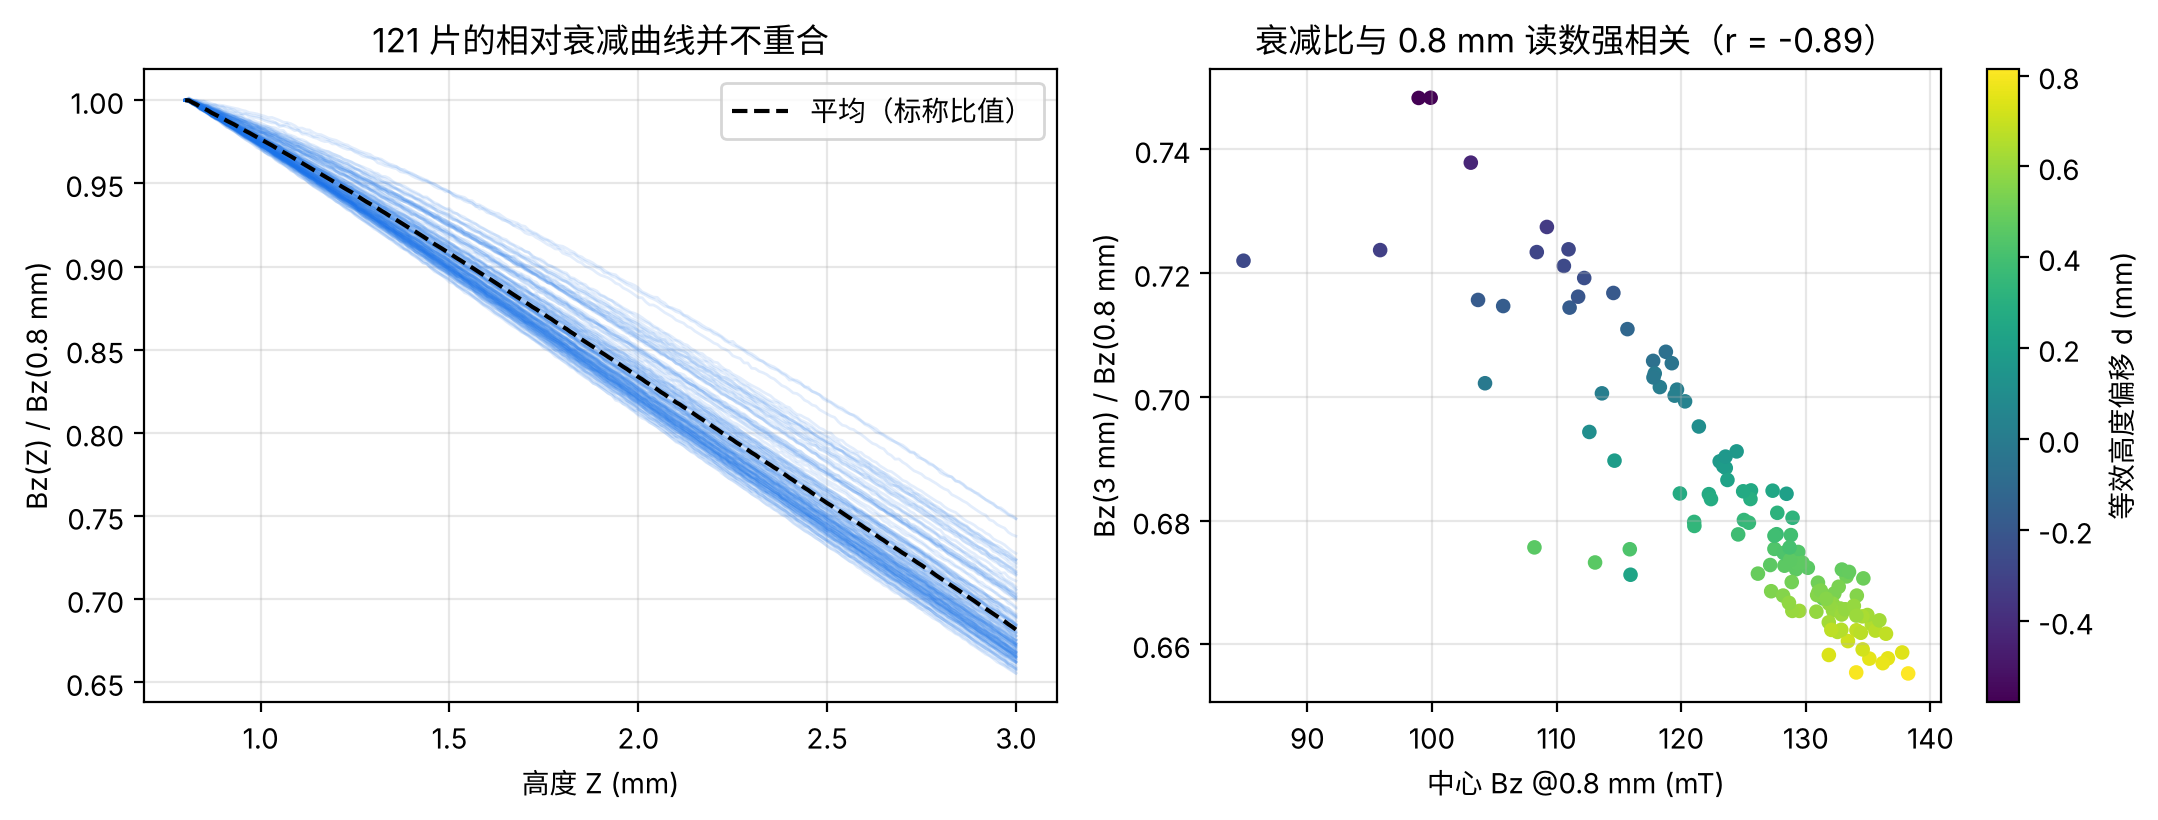

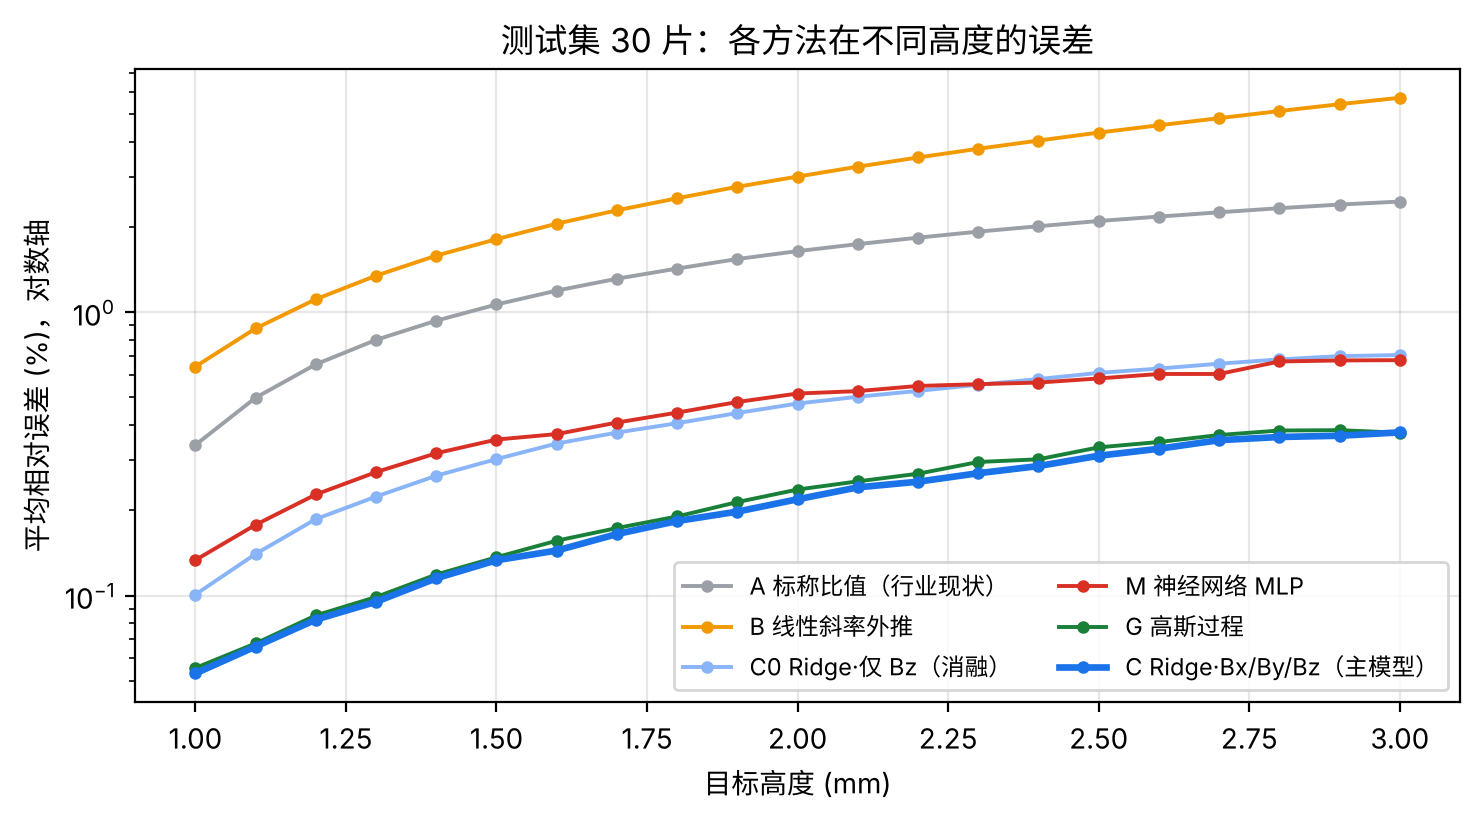

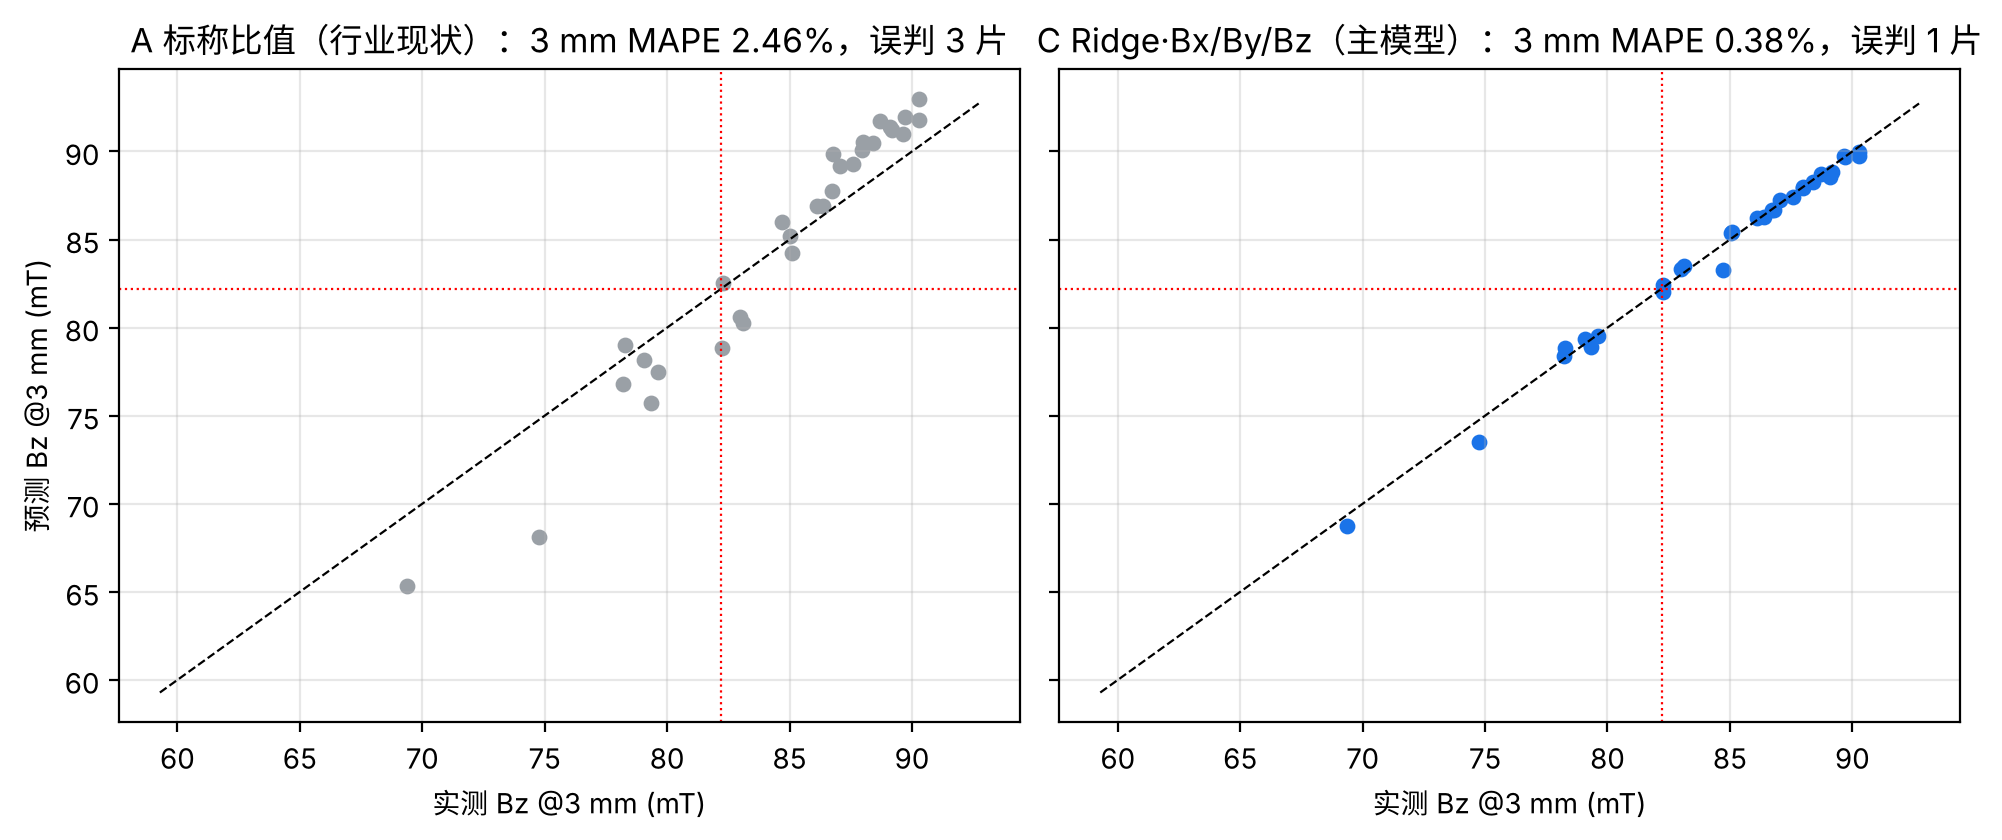

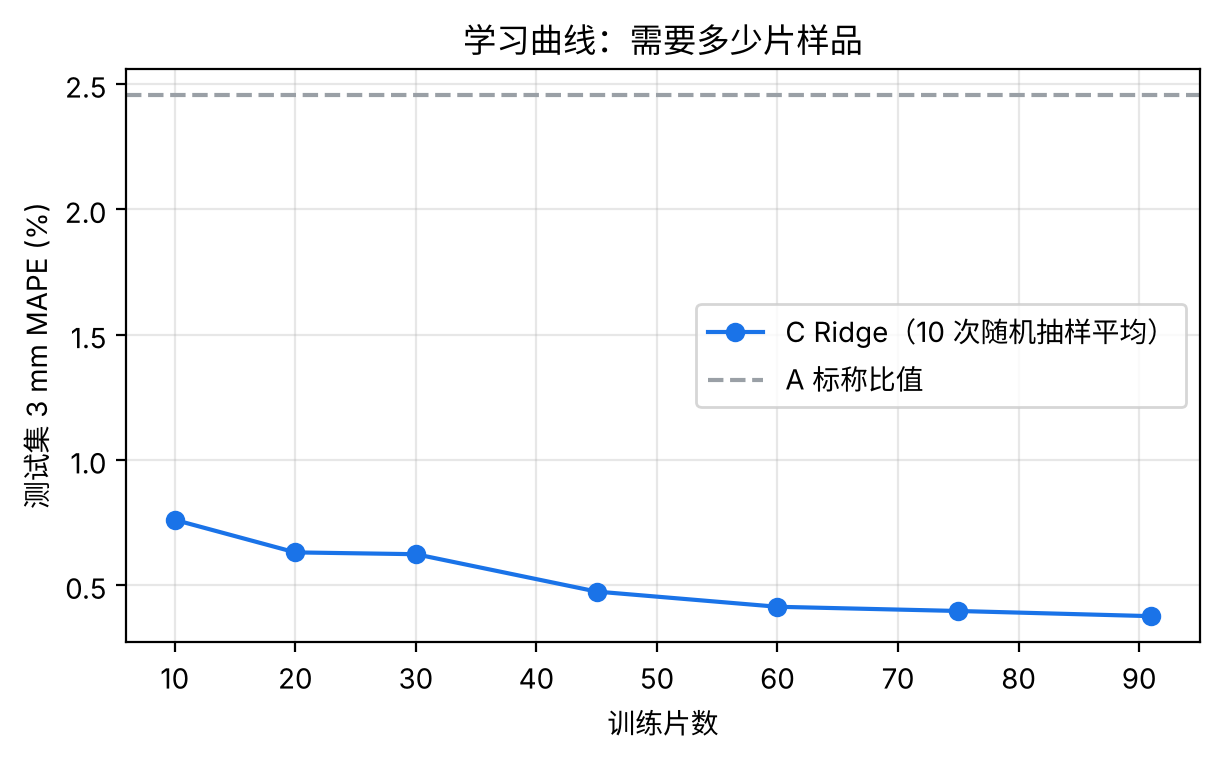

完成：图表保存在 figs/，数值结果保存在 results.json


In [11]:
CL = {"A": "#9aa0a6", "B": "#f29900", "C0": "#8ab4f8", "C": "#1a73e8", "M": "#d93025", "G": "#188038"}
def save(fig, name): fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=180); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for i in range(N): ax[0].plot(ZG, L[i, c, :, 2]/L[i, c, 0, 2], color="#1a73e8", alpha=.12, lw=1)
ax[0].plot(ZG, (L[:, c, :, 2]/L[:, c, :1, 2]).mean(0), "k--", lw=1.5, label="平均（标称比值）")
ax[0].set_xlabel("高度 Z (mm)"); ax[0].set_ylabel("Bz(Z) / Bz(0.8 mm)"); ax[0].set_title("121 片的相对衰减曲线并不重合"); ax[0].legend(); ax[0].grid(alpha=.3)
sc = ax[1].scatter(B08[:, c], r3, c=PHYS[:, 1], cmap="viridis", s=18)
ax[1].set_xlabel("中心 Bz @0.8 mm (mT)"); ax[1].set_ylabel("Bz(3 mm) / Bz(0.8 mm)")
ax[1].set_title(f"衰减比与 0.8 mm 读数强相关（r = {np.corrcoef(r3, B08[:, c])[0, 1]:.2f}）"); plt.colorbar(sc, ax=ax[1], label="等效高度偏移 d (mm)"); ax[1].grid(alpha=.3)
save(fig, "f1_data_overview")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k in ["A", "B", "C0", "M", "G", "C"]:
    ape = (np.abs(PRED[k]-Y[TE])/Y[TE]*100).mean(axis=(0, 1))
    ax.plot(H, ape, "o-", ms=3.5, color=CL[k], lw=2.4 if k == "C" else 1.4, label=NAMES[k])
ax.set_yscale("log"); ax.set_xlabel("目标高度 (mm)"); ax.set_ylabel("平均相对误差 (%)，对数轴"); ax.set_title("测试集 30 片：各方法在不同高度的误差")
ax.legend(fontsize=8.5, ncol=2); ax.grid(alpha=.3); save(fig, "f2_err_vs_height")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.3), sharex=True, sharey=True)
for a_, k in zip(ax, ["A", "C"]):
    a_.scatter(Y[TE, c, J3], PRED[k][:, c, J3], s=22, color=CL[k]); lim = [Y[:, c, J3].min()-2, Y[:, c, J3].max()+2]
    a_.plot(lim, lim, "k--", lw=.8); a_.axhline(SPEC, color="r", lw=.8, ls=":"); a_.axvline(SPEC, color="r", lw=.8, ls=":")
    a_.set_title(f"{NAMES[k]}：3 mm MAPE {RES[k]['MAPE3']:.2f}%，误判 {MIS[k]} 片"); a_.set_xlabel("实测 Bz @3 mm (mT)"); a_.grid(alpha=.3)
ax[0].set_ylabel("预测 Bz @3 mm (mT)"); save(fig, "f3_pred_vs_true_3mm")

fig, ax = plt.subplots(figsize=(6.2, 3.9))
ax.plot(LC_N, LC, "o-", color=CL["C"], label="C Ridge（10 次随机抽样平均）"); ax.axhline(RES["A"]["MAPE3"], ls="--", color=CL["A"], label="A 标称比值")
ax.set_xlabel("训练片数"); ax.set_ylabel("测试集 3 mm MAPE (%)"); ax.set_title("学习曲线：需要多少片样品"); ax.legend(); ax.grid(alpha=.3)
save(fig, "f4_learning_curve")

json.dump(dict(N=N, n_train=len(TR), n_test=len(TE), noise_mT=float(noise), b08_mean=float(B08[:, c].mean()), b08_cv=float(B08[:, c].std()/B08[:, c].mean()*100),
               r3_mean=float(r3.mean()), r3_cv=float(r3.std()/r3.mean()*100), r3_corr=float(np.corrcoef(r3, B08[:, c])[0, 1]),
               phys_res_med=float(np.median(PHYS[:, 2])), d_mean=float(PHYS[:, 1].mean()), d_std=float(PHYS[:, 1].std()),
               test=RES, cv=CV, lc=dict(zip(map(str, LC_N), LC)), spec=SPEC, ok=int(ok_true.sum()), mis=MIS),
          open("results.json", "w"), ensure_ascii=False, indent=1)
print("完成：图表保存在 figs/，数值结果保存在 results.json")

## 4. 结论
- 主模型 C（Ridge · Bx/By/Bz）在测试集 30 片上的平均误差约 0.22%，3 mm 处约 0.38%；行业常用的标称比值 A 在 3 mm 处约 2.46%
- C 比只用 Bz 的 C0 好一倍，说明 Bx/By 带有衰减"形状"的信息
- 小样本下，正则化线性模型优于 MLP，与高斯过程相当
- 学习曲线：约 60 片之后收益变缓

*生成式 AI 披露：本 Notebook 的部分代码与说明文字在 Claude（Anthropic）辅助下编写，实验设计与结果核对由小组成员完成。*